# Day 19 — Transaction Outcome Validation

## Objective

The objective of Day 19 is to investigate transaction-level variables and assess whether a reliable customer-level expenditure outcome can be constructed.

## Research Questions

1. What do quantity and selling_price represent?
2. How are other_discount and coupon_discount recorded?
3. Can transaction expenditure be calculated reliably?
4. How should transaction records be aggregated at customer level?
5. Is the constructed outcome suitable for causal analysis?

## Expected Outputs

- Transaction variable validation.
- Discount analysis.
- Expenditure calculation assessment.
- Customer-level spending summary.
- Outcome feasibility assessment.

## Important Note

Descriptive transaction calculations do not automatically represent actual customer expenditure. Variable definitions and measurement assumptions must be validated before causal modelling.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load transaction dataset
transaction_data = pd.read_csv(
    "../data/raw/customer_transaction_data.csv"
)

print("Dataset loaded successfully!")
print("Shape:", transaction_data.shape)

transaction_data.head()

Dataset loaded successfully!
Shape: (1324566, 7)


,date,customer_id,item_id,quantity,selling_price,other_discount,coupon_discount
0,2012-01-02,1501,26830,1,35.26,-10.69,0.0
1,2012-01-02,1501,54253,1,53.43,-13.89,0.0
2,2012-01-02,1501,31962,1,106.50,-14.25,0.0
3,2012-01-02,1501,33647,1,67.32,0.00,0.0
4,2012-01-02,1501,48199,1,71.24,-28.14,0.0


In [2]:
# Display column names
print("Columns:")
print(transaction_data.columns.tolist())

# Display data types
print("\nData Types:")
print(transaction_data.dtypes)

# Dataset information
print("\nDataset Information:")
transaction_data.info()

Columns:
['date', 'customer_id', 'item_id', 'quantity', 'selling_price', 'other_discount', 'coupon_discount']

Data Types:
date                   str
customer_id          int64
item_id              int64
quantity             int64
selling_price      float64
other_discount     float64
coupon_discount    float64
dtype: object

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1324566 entries, 0 to 1324565
Data columns (total 7 columns):
 #   Column           Non-Null Count    Dtype  
---  ------           --------------    -----  
 0   date             1324566 non-null  str    
 1   customer_id      1324566 non-null  int64  
 2   item_id          1324566 non-null  int64  
 3   quantity         1324566 non-null  int64  
 4   selling_price    1324566 non-null  float64
 5   other_discount   1324566 non-null  float64
 6   coupon_discount  1324566 non-null  float64
dtypes: float64(3), int64(3), str(1)
memory usage: 83.4 MB


In [3]:
# Check missing values
print("Missing Values:")
print(transaction_data.isnull().sum())

# Check duplicate records
print("\nTotal Duplicate Rows:")
print(transaction_data.duplicated().sum())

# Check unique customers and items
print("\nUnique Customers:",
      transaction_data['customer_id'].nunique())

print("Unique Items:",
      transaction_data['item_id'].nunique())

print("Unique Transaction Dates:",
      transaction_data['date'].nunique())

Missing Values:
date               0
customer_id        0
item_id            0
quantity           0
selling_price      0
other_discount     0
coupon_discount    0
dtype: int64

Total Duplicate Rows:
2916

Unique Customers: 1582
Unique Items: 74063
Unique Transaction Dates: 549


In [4]:
# Convert date column into datetime
transaction_data['date'] = pd.to_datetime(
    transaction_data['date'],
    errors='coerce'
)

# Date range
print("Earliest Transaction Date:",
      transaction_data['date'].min())

print("Latest Transaction Date:",
      transaction_data['date'].max())

# Monthly transaction counts
monthly_transactions = (
    transaction_data
    .set_index('date')
    .resample('ME')
    .size()
)

print("\nMonthly Transaction Counts:")
print(monthly_transactions)

Earliest Transaction Date: 2012-01-02 00:00:00
Latest Transaction Date: 2013-07-03 00:00:00

Monthly Transaction Counts:
date
2012-01-31    12382
2012-02-29    25073
2012-03-31    46730
2012-04-30    68340
2012-05-31    79093
2012-06-30    79091
2012-07-31    81022
2012-08-31    84037
2012-09-30    85301
2012-10-31    86648
2012-11-30    86632
2012-12-31    88114
2013-01-31    86228
2013-02-28    78681
2013-03-31    85970
2013-04-30    79046
2013-05-31    86044
2013-06-30    79757
2013-07-31     6377
Freq: ME, dtype: int64


Quantity Summary:
count    1.324566e+06
mean     1.306633e+02
std      1.311545e+03
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      8.963800e+04
Name: quantity, dtype: float64

Unique Quantity Values:
9252


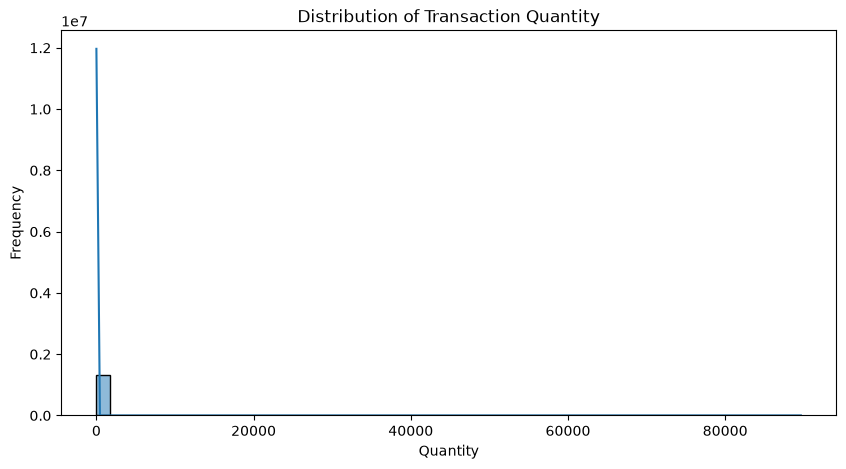

In [5]:
# Quantity statistical summary
print("Quantity Summary:")
print(transaction_data['quantity'].describe())

# Unique quantity values
print("\nUnique Quantity Values:")
print(transaction_data['quantity'].nunique())

# Quantity distribution
plt.figure(figsize=(10, 5))
sns.histplot(
    transaction_data['quantity'],
    bins=50,
    kde=True
)
plt.title("Distribution of Transaction Quantity")
plt.xlabel("Quantity")
plt.ylabel("Frequency")
plt.show()

Selling Price Summary:
count    1.324566e+06
mean     1.146036e+02
std      1.529053e+02
min      3.600000e-01
25%      4.916000e+01
50%      7.801000e+01
75%      1.243100e+02
max      1.780964e+04
Name: selling_price, dtype: float64

Unique Selling Prices: 4923


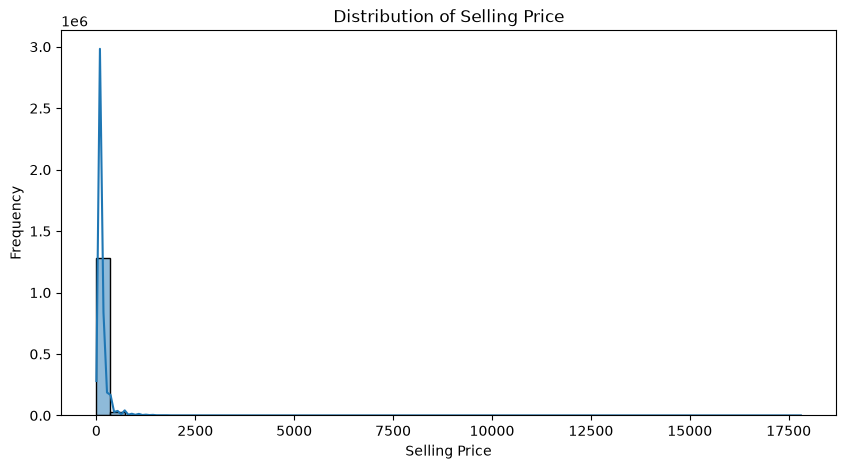

In [6]:
# Selling price statistical summary
print("Selling Price Summary:")
print(transaction_data['selling_price'].describe())

# Check unique selling prices
print("\nUnique Selling Prices:",
      transaction_data['selling_price'].nunique())

# Selling price distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    transaction_data['selling_price'],
    bins=50,
    kde=True
)

plt.title("Distribution of Selling Price")
plt.xlabel("Selling Price")
plt.ylabel("Frequency")

plt.show()

In [7]:
discount_columns = ['other_discount', 'coupon_discount']

for col in discount_columns:
    print(f"\n{col} Summary:")
    print(transaction_data[col].describe())

    print("\nNegative values:", (transaction_data[col] < 0).sum())
    print("Zero values:", (transaction_data[col] == 0).sum())
    print("Positive values:", (transaction_data[col] > 0).sum())


other_discount Summary:
count    1.324566e+06
mean    -1.776871e+01
std      3.788867e+01
min     -3.120310e+03
25%     -2.315000e+01
50%     -1.780000e+00
75%      0.000000e+00
max      0.000000e+00
Name: other_discount, dtype: float64

Negative values: 671649
Zero values: 652917
Positive values: 0

coupon_discount Summary:
count    1.324566e+06
mean    -5.948983e-01
std      7.069367e+00
min     -1.992230e+03
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      0.000000e+00
Name: coupon_discount, dtype: float64

Negative values: 21286
Zero values: 1303280
Positive values: 0


Discount Pattern Analysis:
Both Discounts           13619
Only Other Discount     658030
Only Coupon Discount      7667
No Discounts            645250
dtype: int64


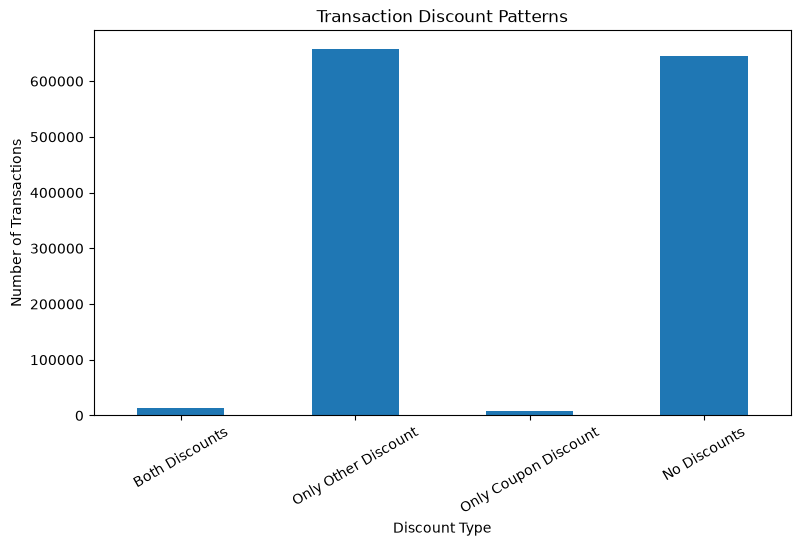

In [8]:
# Create discount indicators
transaction_data['has_other_discount'] = (
    transaction_data['other_discount'] < 0
)

transaction_data['has_coupon_discount'] = (
    transaction_data['coupon_discount'] < 0
)

# Count discount combinations
discount_patterns = pd.Series({
    'Both Discounts': (
        transaction_data['has_other_discount'] &
        transaction_data['has_coupon_discount']
    ).sum(),

    'Only Other Discount': (
        transaction_data['has_other_discount'] &
        ~transaction_data['has_coupon_discount']
    ).sum(),

    'Only Coupon Discount': (
        ~transaction_data['has_other_discount'] &
        transaction_data['has_coupon_discount']
    ).sum(),

    'No Discounts': (
        ~transaction_data['has_other_discount'] &
        ~transaction_data['has_coupon_discount']
    ).sum()
})

print("Discount Pattern Analysis:")
print(discount_patterns)

# Visualize
discount_patterns.plot(
    kind='bar',
    figsize=(9, 5),
    title='Transaction Discount Patterns'
)

plt.xlabel("Discount Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=30)
plt.show()

Correlation Matrix:
               quantity  selling_price
quantity       1.000000       0.672741
selling_price  0.672741       1.000000


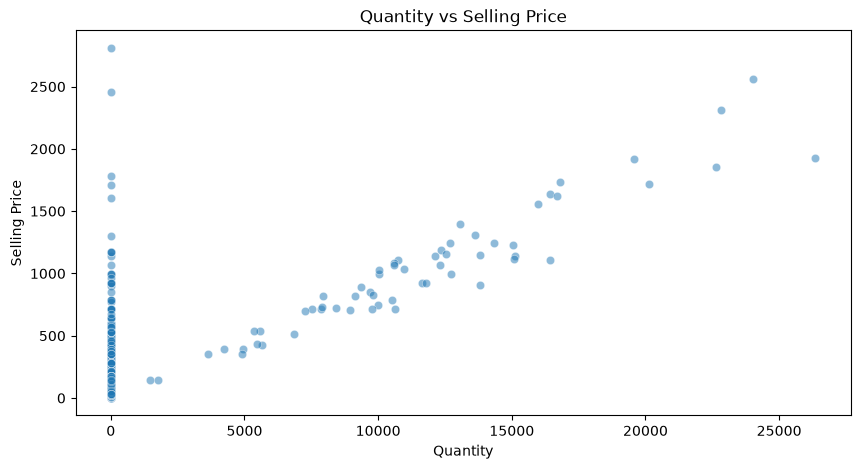

In [9]:
# Calculate correlation
correlation = transaction_data[
    ['quantity', 'selling_price']
].corr()

print("Correlation Matrix:")
print(correlation)

# Scatter plot using a sample
sample_data = transaction_data.sample(
    n=min(5000, len(transaction_data)),
    random_state=42
)

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=sample_data,
    x='quantity',
    y='selling_price',
    alpha=0.5
)

plt.title("Quantity vs Selling Price")
plt.xlabel("Quantity")
plt.ylabel("Selling Price")
plt.show()

In [10]:
# Calculate provisional price per quantity
transaction_data['price_per_quantity'] = (
    transaction_data['selling_price'] /
    transaction_data['quantity'].replace(0, np.nan)
)

# Summary statistics
print("Price per Quantity Summary:")
print(transaction_data['price_per_quantity'].describe())

# Compare quantity and ratio
print("\nCorrelation:")
print(
    transaction_data[
        ['quantity', 'selling_price', 'price_per_quantity']
    ].corr()
)

# Display sample records
transaction_data[
    ['item_id', 'quantity', 'selling_price', 'price_per_quantity']
].head(10)

Price per Quantity Summary:
count    1.324566e+06
mean     8.770231e+01
std      9.287411e+01
min      5.911488e-02
25%      3.562000e+01
50%      7.088000e+01
75%      1.065000e+02
max      1.780964e+04
Name: price_per_quantity, dtype: float64

Correlation:
                    quantity  selling_price  price_per_quantity
quantity            1.000000       0.672741           -0.093137
selling_price       0.672741       1.000000            0.565473
price_per_quantity -0.093137       0.565473            1.000000


,item_id,quantity,selling_price,price_per_quantity
0,26830,1,35.26,35.260000
1,54253,1,53.43,53.430000
2,31962,1,106.50,106.500000
3,33647,1,67.32,67.320000
4,48199,1,71.24,71.240000
5,57397,1,71.24,71.240000
6,12424,1,106.50,106.500000
7,14930,1,110.07,110.070000
8,16657,1,89.05,89.050000
9,10537,3,32.06,10.686667


In [11]:
# Group transactions by item
item_analysis = (
    transaction_data
    .groupby('item_id')
    .agg(
        transaction_count=('item_id', 'size'),
        avg_quantity=('quantity', 'mean'),
        median_quantity=('quantity', 'median'),
        avg_selling_price=('selling_price', 'mean'),
        avg_price_per_quantity=('price_per_quantity', 'mean')
    )
    .reset_index()
)

# Sort by transaction frequency
item_analysis = item_analysis.sort_values(
    by='transaction_count',
    ascending=False
)

print("Top 15 Frequently Sold Items:")
display(item_analysis.head(15))

Top 15 Frequently Sold Items:


,item_id,transaction_count,avg_quantity,median_quantity,avg_selling_price,avg_price_per_quantity
49006,49009,13540,10871.494313,10573.0,931.305675,0.086038
34045,34047,6308,1.170419,1.0,99.298992,85.513759
13172,13174,3879,1.105182,1.0,38.744555,35.058349
45499,45502,3292,1.639125,1.0,177.682479,114.849907
29845,29847,2276,1.585237,1.0,56.259767,35.499694
18154,18156,2226,1.244834,1.0,65.402363,52.585347
28631,28633,2152,1.549257,1.0,63.895990,42.167784
32989,32991,2101,1.267016,1.0,65.228529,51.587270
9279,9281,2007,2.712506,2.0,46.323468,17.104852
8523,8525,1922,1.441207,1.0,77.050068,53.515535


In [12]:
# Calculate item-level price variation
item_price_variation = (
    transaction_data
    .groupby('item_id')
    .agg(
        transaction_count=('selling_price', 'count'),
        min_price=('selling_price', 'min'),
        max_price=('selling_price', 'max'),
        mean_price=('selling_price', 'mean'),
        std_price=('selling_price', 'std')
    )
    .reset_index()
)

# Keep frequently observed items
frequent_items = item_price_variation[
    item_price_variation['transaction_count'] >= 50
].copy()

# Calculate coefficient of variation
frequent_items['price_cv'] = (
    frequent_items['std_price'] /
    frequent_items['mean_price']
)

# Sort by price variation
frequent_items = frequent_items.sort_values(
    by='price_cv',
    ascending=False
)

display(frequent_items.head(15))

,item_id,transaction_count,min_price,max_price,mean_price,std_price,price_cv
16442,16444,140,3.56,352.64,15.340857,32.456035,2.115660
11244,11246,94,35.62,1574.76,81.618617,161.199755,1.975037
47341,47344,71,3.56,138.92,12.239155,22.014406,1.798687
70830,70834,60,89.05,2137.20,173.463500,283.932922,1.636845
57971,57974,365,9.62,459.50,25.226082,39.282542,1.557219
56622,56625,104,28.14,877.68,54.198077,83.902047,1.548063
8971,8973,126,8.90,320.58,31.913730,48.584116,1.522358
22759,22761,130,23.51,423.17,55.551615,82.803191,1.490563
20438,20440,263,3.56,284.96,15.276464,22.457769,1.470089
28631,28633,2152,28.14,2806.50,63.895990,91.378616,1.430115


In [13]:
# Candidate A: Recorded selling price
transaction_data['expenditure_candidate_A'] = (
    transaction_data['selling_price']
)

# Candidate B: Selling price adjusted for discounts
transaction_data['expenditure_candidate_B'] = (
    transaction_data['selling_price']
    + transaction_data['other_discount']
    + transaction_data['coupon_discount']
)

# Compare both candidates
comparison = transaction_data[
    [
        'expenditure_candidate_A',
        'expenditure_candidate_B'
    ]
].describe()

display(comparison)

# Check negative values
print(
    "Negative values in Candidate A:",
    (transaction_data['expenditure_candidate_A'] < 0).sum()
)

print(
    "Negative values in Candidate B:",
    (transaction_data['expenditure_candidate_B'] < 0).sum()
)

,expenditure_candidate_A,expenditure_candidate_B
count,1.324566e+06,1.324566e+06
mean,1.146036e+02,9.624003e+01
std,1.529053e+02,1.479755e+02
min,3.600000e-01,-1.424440e+03
25%,4.916000e+01,3.526000e+01
50%,7.801000e+01,6.376000e+01
75%,1.243100e+02,1.065000e+02
max,1.780964e+04,1.602864e+04


Negative values in Candidate A: 0
Negative values in Candidate B: 27524


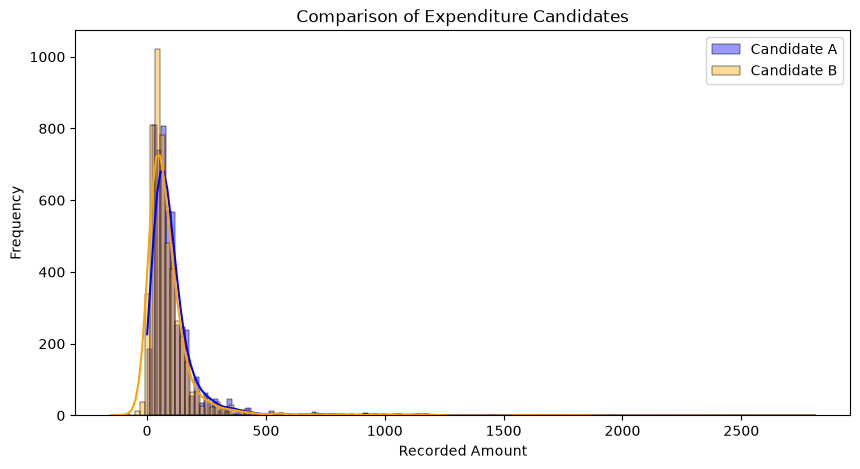

In [14]:
# Sample records for visualization
sample_data = transaction_data.sample(
    n=min(5000, len(transaction_data)),
    random_state=42
)

plt.figure(figsize=(10, 5))

sns.histplot(
    sample_data['expenditure_candidate_A'],
    color='blue',
    label='Candidate A',
    kde=True,
    alpha=0.4
)

sns.histplot(
    sample_data['expenditure_candidate_B'],
    color='orange',
    label='Candidate B',
    kde=True,
    alpha=0.4
)

plt.title("Comparison of Expenditure Candidates")
plt.xlabel("Recorded Amount")
plt.ylabel("Frequency")
plt.legend()
plt.show()

In [15]:
# Calculate discount impact
transaction_data['total_discount'] = (
    transaction_data['other_discount']
    + transaction_data['coupon_discount']
)

# Discount impact summary
print("Total Discount Summary:")
print(transaction_data['total_discount'].describe())

# Check whether discounts exceed selling price
excess_discount = (
    transaction_data['total_discount'].abs()
    > transaction_data['selling_price']
)

print("\nDiscount exceeds selling price:",
      excess_discount.sum())

# Check negative adjusted expenditure
negative_expenditure = (
    transaction_data['expenditure_candidate_B'] < 0
)

print("Negative adjusted expenditure:",
      negative_expenditure.sum())

# Display suspicious records
display(
    transaction_data.loc[
        excess_discount | negative_expenditure,
        [
            'customer_id',
            'item_id',
            'quantity',
            'selling_price',
            'other_discount',
            'coupon_discount',
            'expenditure_candidate_B'
        ]
    ].head(10)
)

Total Discount Summary:
count    1.324566e+06
mean    -1.836360e+01
std      3.929699e+01
min     -3.258160e+03
25%     -2.458000e+01
50%     -3.210000e+00
75%      0.000000e+00
max      0.000000e+00
Name: total_discount, dtype: float64

Discount exceeds selling price: 27524
Negative adjusted expenditure: 27524


,customer_id,item_id,quantity,selling_price,other_discount,coupon_discount,expenditure_candidate_B
38,679,15351,1,42.39,-42.74,0.00,-0.35
45,679,22274,1,44.52,-47.73,0.00,-3.21
100,464,14172,1,35.26,-35.62,0.00,-0.36
104,464,16381,1,48.80,-14.96,-35.62,-1.78
143,464,45277,1,71.24,-53.07,-35.62,-17.45
165,1457,27564,2,54.50,-35.62,-19.59,-0.71
253,138,32321,1,141.41,-143.19,0.00,-1.78
271,188,15255,1,42.39,-42.74,0.00,-0.35
547,221,34688,2,35.62,-49.16,0.00,-13.54
623,1191,17233,1,28.14,-32.06,0.00,-3.92


In [16]:
# Customer-level aggregation
customer_spending = (
    transaction_data
    .groupby('customer_id')
    .agg(
        total_transactions=('customer_id', 'size'),
        total_quantity=('quantity', 'sum'),
        total_selling_price=('expenditure_candidate_A', 'sum'),
        total_adjusted_amount=('expenditure_candidate_B', 'sum'),
        total_other_discount=('other_discount', 'sum'),
        total_coupon_discount=('coupon_discount', 'sum')
    )
    .reset_index()
)

print("Customer-level dataset shape:",
      customer_spending.shape)

display(customer_spending.head(10))

Customer-level dataset shape: (1582, 7)


,customer_id,total_transactions,total_quantity,total_selling_price,total_adjusted_amount,total_other_discount,total_coupon_discount
0,1,1048,1227,98513.93,79366.70,-17030.40,-2116.83
1,2,419,474,43100.03,35798.74,-7051.95,-249.34
2,3,705,8163,73050.27,54857.20,-16013.53,-2179.54
3,4,220,280,33973.22,30956.98,-2927.19,-89.05
4,5,792,93353,103615.10,92707.20,-10817.07,-90.83
5,6,583,707,59508.22,52101.47,-6997.13,-409.62
6,7,1053,57763,107477.03,87944.20,-18747.40,-785.43
7,8,1318,1334454,299482.15,261865.71,-31011.15,-6605.29
8,9,557,117820,57275.87,45071.89,-11753.75,-450.23
9,10,491,81165,50960.30,45323.84,-5636.46,0.00


In [17]:
# Customer-level aggregation
customer_spending = (
    transaction_data
    .groupby('customer_id')
    .agg(
        total_transactions=('customer_id', 'size'),
        total_quantity=('quantity', 'sum'),
        total_selling_price=('expenditure_candidate_A', 'sum'),
        total_adjusted_amount=('expenditure_candidate_B', 'sum'),
        total_other_discount=('other_discount', 'sum'),
        total_coupon_discount=('coupon_discount', 'sum')
    )
    .reset_index()
)

print("Customer-level dataset shape:",
      customer_spending.shape)

display(customer_spending.head(10))

Customer-level dataset shape: (1582, 7)


,customer_id,total_transactions,total_quantity,total_selling_price,total_adjusted_amount,total_other_discount,total_coupon_discount
0,1,1048,1227,98513.93,79366.70,-17030.40,-2116.83
1,2,419,474,43100.03,35798.74,-7051.95,-249.34
2,3,705,8163,73050.27,54857.20,-16013.53,-2179.54
3,4,220,280,33973.22,30956.98,-2927.19,-89.05
4,5,792,93353,103615.10,92707.20,-10817.07,-90.83
5,6,583,707,59508.22,52101.47,-6997.13,-409.62
6,7,1053,57763,107477.03,87944.20,-18747.40,-785.43
7,8,1318,1334454,299482.15,261865.71,-31011.15,-6605.29
8,9,557,117820,57275.87,45071.89,-11753.75,-450.23
9,10,491,81165,50960.30,45323.84,-5636.46,0.00


In [18]:
# Statistical summary of customer spending
print("Customer Spending Summary:")
display(
    customer_spending[
        [
            'total_transactions',
            'total_quantity',
            'total_selling_price',
            'total_adjusted_amount'
        ].describe()
    ]
)

# Plot customer spending distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    customer_spending['total_adjusted_amount'],
    bins=50,
    kde=True
)

plt.title("Customer-Level Adjusted Amount Distribution")
plt.xlabel("Total Adjusted Amount")
plt.ylabel("Number of Customers")

plt.show()

Customer Spending Summary:


AttributeError: 'list' object has no attribute 'describe'

Customer Spending Summary:


,total_transactions,total_quantity,total_selling_price,total_adjusted_amount
count,1582.000000,1.582000e+03,1582.000000,1582.000000
mean,837.273072,1.094009e+05,95954.535841,80579.183919
std,604.525972,2.050266e+05,75260.501831,65568.182808
min,79.000000,8.800000e+01,7806.080000,3465.890000
25%,416.000000,9.247500e+02,45327.190000,36704.605000
50%,664.000000,1.876850e+04,72597.885000,59453.945000
75%,1078.500000,1.294910e+05,124123.050000,102353.552500
max,4522.000000,2.617544e+06,583638.780000,529971.400000


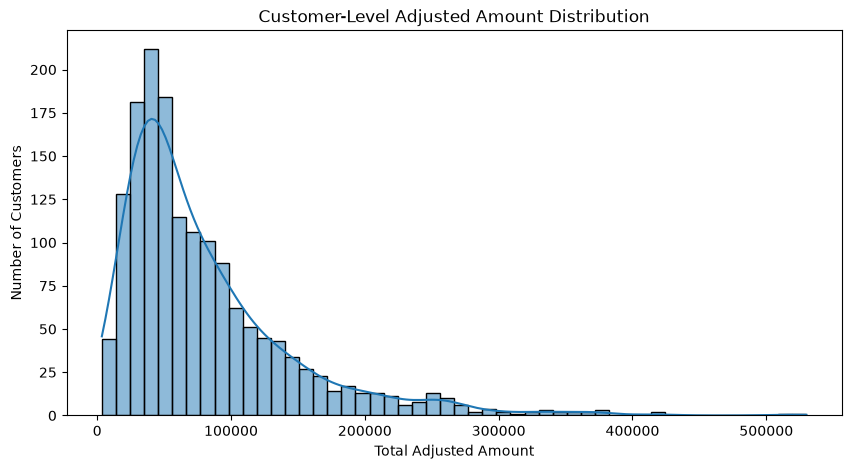

In [19]:
# Statistical summary of customer spending
print("Customer Spending Summary:")

display(
    customer_spending[
        [
            'total_transactions',
            'total_quantity',
            'total_selling_price',
            'total_adjusted_amount'
        ]
    ].describe()
)

# Plot customer spending distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    customer_spending['total_adjusted_amount'],
    bins=50,
    kde=True
)

plt.title("Customer-Level Adjusted Amount Distribution")
plt.xlabel("Total Adjusted Amount")
plt.ylabel("Number of Customers")

plt.show()

In [20]:
# Sort customers by adjusted amount
top_customers = customer_spending.sort_values(
    by='total_adjusted_amount',
    ascending=False
)

# Display top 15 customers
display(
    top_customers[
        [
            'customer_id',
            'total_transactions',
            'total_quantity',
            'total_adjusted_amount'
        ]
    ].head(15)
)

# Calculate spending percentiles
print("\nSpending Percentiles:")

print(
    customer_spending['total_adjusted_amount']
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99, 1.00])
)

,customer_id,total_transactions,total_quantity,total_adjusted_amount
1010,1011,3862,1598625,529971.40
1465,1466,3443,930913,509858.53
897,898,3248,1394845,421534.68
1554,1555,4522,457828,415207.40
910,911,3600,78844,381855.33
258,259,2748,573626,378354.59
710,711,4173,7271,372355.68
1238,1239,2327,435355,370168.66
626,627,3429,1052504,367740.68
455,456,2398,1137624,360341.43



Spending Percentiles:
0.50     59453.9450
0.75    102353.5525
0.90    163669.4570
0.95    216360.7590
0.99    329219.7060
1.00    529971.4000
Name: total_adjusted_amount, dtype: float64


In [21]:
# Sort customers by adjusted spending
sorted_customers = customer_spending.sort_values(
    by='total_adjusted_amount',
    ascending=False
).copy()

# Calculate top 10% customer count
top_10_count = int(np.ceil(len(sorted_customers) * 0.10))

# Calculate total spending
total_spending = sorted_customers['total_adjusted_amount'].sum()

# Calculate top 10% spending
top_10_spending = (
    sorted_customers.head(top_10_count)
    ['total_adjusted_amount'].sum()
)

# Calculate concentration percentage
top_10_percentage = (
    top_10_spending / total_spending
) * 100

print("Total Customers:", len(sorted_customers))
print("Top 10% Customers:", top_10_count)
print("Total Adjusted Spending:", total_spending)
print("Top 10% Spending:", top_10_spending)
print("Top 10% Spending Contribution:", round(top_10_percentage, 2), "%")

Total Customers: 1582
Top 10% Customers: 159
Total Adjusted Spending: 127476268.96000001
Top 10% Spending: 37218397.190000005
Top 10% Spending Contribution: 29.2 %


Customer Spending vs Transaction Frequency:


,total_transactions,total_adjusted_amount
total_transactions,1.000000,0.903139
total_adjusted_amount,0.903139,1.000000


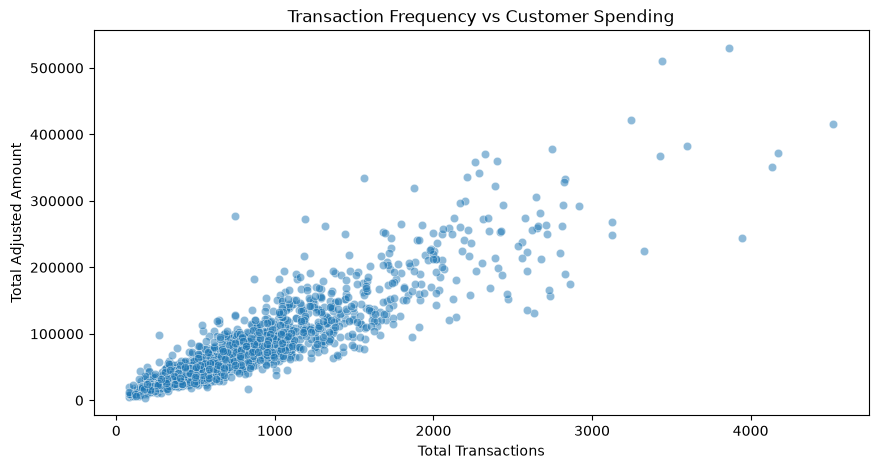

In [22]:
# Calculate correlation
correlation = customer_spending[
    ['total_transactions', 'total_adjusted_amount']
].corr()

print("Customer Spending vs Transaction Frequency:")
display(correlation)

# Scatter plot
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=customer_spending,
    x='total_transactions',
    y='total_adjusted_amount',
    alpha=0.5
)

plt.title("Transaction Frequency vs Customer Spending")
plt.xlabel("Total Transactions")
plt.ylabel("Total Adjusted Amount")

plt.show()

In [23]:
# Create transaction frequency groups
customer_spending['frequency_group'] = pd.qcut(
    customer_spending['total_transactions'],
    q=4,
    labels=['Low', 'Medium', 'High', 'Very High'],
    duplicates='drop'
)

# Group-level analysis
frequency_analysis = (
    customer_spending
    .groupby('frequency_group', observed=True)
    .agg(
        customer_count=('customer_id', 'count'),
        avg_transactions=('total_transactions', 'mean'),
        avg_adjusted_spending=('total_adjusted_amount', 'mean'),
        median_adjusted_spending=('total_adjusted_amount', 'median')
    )
    .reset_index()
)

display(frequency_analysis)

,frequency_group,customer_count,avg_transactions,avg_adjusted_spending,median_adjusted_spending
0,Low,398,283.653266,28325.970754,26731.020
1,Medium,394,536.307107,48895.324391,46776.775
2,High,394,858.847716,82028.061523,78055.010
3,Very High,396,1671.669192,163178.582197,144237.465


In [24]:
# Compare customer-level spending candidates

customer_spending['spending_difference'] = (
    customer_spending['total_selling_price']
    - customer_spending['total_adjusted_amount']
)

customer_spending['discount_impact_percentage'] = (
    customer_spending['spending_difference']
    / customer_spending['total_selling_price'].replace(0, np.nan)
) * 100

print("Customer-Level Outcome Comparison:")

display(
    customer_spending[
        [
            'total_selling_price',
            'total_adjusted_amount',
            'spending_difference',
            'discount_impact_percentage'
        ]
    ].describe()
)

Customer-Level Outcome Comparison:


,total_selling_price,total_adjusted_amount,spending_difference,discount_impact_percentage
count,1582.000000,1582.000000,1582.000000,1582.000000
mean,95954.535841,80579.183919,15375.351922,16.981735
std,75260.501831,65568.182808,12236.760870,6.740776
min,7806.080000,3465.890000,568.840000,2.292972
25%,45327.190000,36704.605000,7039.972500,12.435158
50%,72597.885000,59453.945000,11913.890000,15.866103
75%,124123.050000,102353.552500,19779.290000,20.074962
max,583638.780000,529971.400000,109943.910000,72.860016


In [25]:
# Validate customer-level spending candidates

for col in [
    'total_selling_price',
    'total_adjusted_amount'
]:
    print(f"\n{col}")

    print("Missing:", customer_spending[col].isna().sum())
    print("Zero:", (customer_spending[col] == 0).sum())
    print("Negative:", (customer_spending[col] < 0).sum())
    print("Positive:", (customer_spending[col] > 0).sum())


total_selling_price
Missing: 0
Zero: 0
Negative: 0
Positive: 1582

total_adjusted_amount
Missing: 0
Zero: 0
Negative: 0
Positive: 1582


In [26]:
# Export customer-level spending analysis

customer_spending.to_csv(
    "../reports/day19_customer_spending_analysis.csv",
    index=False
)

print("Customer-level analysis exported successfully!")

print("Shape:", customer_spending.shape)

Customer-level analysis exported successfully!
Shape: (1582, 10)


In [27]:
# Load exported customer-level dataset
verified_data = pd.read_csv(
    "../reports/day19_customer_spending_analysis.csv"
)

print("File verification successful!")
print("Shape:", verified_data.shape)

print("\nColumns:")
print(verified_data.columns.tolist())

display(verified_data.head())

File verification successful!
Shape: (1582, 10)

Columns:
['customer_id', 'total_transactions', 'total_quantity', 'total_selling_price', 'total_adjusted_amount', 'total_other_discount', 'total_coupon_discount', 'frequency_group', 'spending_difference', 'discount_impact_percentage']


,customer_id,total_transactions,total_quantity,total_selling_price,total_adjusted_amount,total_other_discount,total_coupon_discount,frequency_group,spending_difference,discount_impact_percentage
0,1,1048,1227,98513.93,79366.70,-17030.40,-2116.83,High,19147.23,19.436064
1,2,419,474,43100.03,35798.74,-7051.95,-249.34,Medium,7301.29,16.940336
2,3,705,8163,73050.27,54857.20,-16013.53,-2179.54,High,18193.07,24.904863
3,4,220,280,33973.22,30956.98,-2927.19,-89.05,Low,3016.24,8.878287
4,5,792,93353,103615.10,92707.20,-10817.07,-90.83,High,10907.90,10.527327


# Day 19 — Transaction Outcome Validation: Preliminary Findings

## Work Completed

1. Inspected transaction columns and data types.
2. Checked missing values and duplicate records.
3. Investigated transaction date coverage.
4. Analyzed quantity and selling price distributions.
5. Examined other and coupon discounts.
6. Investigated item-level price variation.
7. Compared two expenditure candidates.
8. Aggregated transactions at customer level.
9. Analyzed customer spending distributions.
10. Investigated spending concentration and transaction frequency.
11. Validated customer-level spending values.
12. Exported and verified the customer-level analysis.

## Important Findings

- Transaction-level variables require further semantic validation.
- Discount values are recorded as negative amounts in the observed data.
- Fuel transactions exhibit unusual quantity patterns.
- Customer-level aggregation provides exploratory spending measures.
- Discount-adjusted spending is a candidate measure, not a confirmed expenditure outcome.

## Research Limitations

- The exact meaning and units of quantity require verification.
- The definition of selling_price must be established.
- The correct discount calculation remains unconfirmed.
- Customer-level spending candidates cannot yet be treated as validated causal outcomes.
- Extreme values require investigation rather than automatic removal.

## Output File

`day19_customer_spending_analysis.csv`

## Conclusion

Day 19 established an exploratory customer-level transaction analysis. Further documentation and validation are required before selecting a reliable expenditure outcome for causal modelling.